## On/off statistics

Analyses on/off bout statistics by fish.

Distribution of ON and OFF grouped by age.

Figures are saved to the project `figures/` directory and to `on_off/media/`.

Import libraries:

In [1]:
import numpy as np
import matplotlib.pyplot as plt
def inline():
    %matplotlib inline
    plt.close('all')
def widget():
    %matplotlib widget
    plt.close('all')
import sys
from pathlib import Path
_code = Path.cwd() if (Path.cwd() / "paths.py").exists() else Path.cwd().parent
if str(_code.resolve()) not in [str(Path(p).resolve()) for p in sys.path]:
    sys.path.insert(0, str(_code.resolve()))
from paths import PROJECT_ROOT, DATA_DIR, FIGURES_DIR, notebook_media_dir
%load_ext autoreload
%autoreload 2
    
from functions.utilities import *
from functions.freely_swimming import *
from functions.MC_freely_swimming import *
from functions.MC_plots import *

import os
import h5py
from ipywidgets import interact,IntSlider
from scipy import fft
from scipy.ndimage import gaussian_filter
from skimage import io
import pickle
from scipy import fft
from sklearn.preprocessing import scale
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable
from scipy.stats import iqr
import pandas as pd
from scipy.interpolate import interp1d

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


In [2]:
from functions.MC_utilities import *
[color_y, color_m, color_o, color_low_boutID, color_med_boutID, color_high_boutID, color_cont, color_bout] = get_colors()
group_colors = [color_y, color_m, color_o]

In [3]:
print(os.getcwd()) 

<repo>/code/on_off


In [4]:
# Paths from code/paths.py (project root, data, figures, local media)
path = str(PROJECT_ROOT)
path_data = str(DATA_DIR)
path_figures = str(FIGURES_DIR)
path_media = str(notebook_media_dir("on_off"))
print(path, path_data, path_figures)

<repo> <repo>/data <repo>/figures


#### Import data:

In [5]:
fish_ids_young=['13_06May24_1','13_30Oct24_3','13_30Oct24_4','14_27Mar24_1','14_31Oct24_1']
index_y = list(range(0, len(fish_ids_young)))
print(index_y)

[0, 1, 2, 3, 4]


In [6]:
fish_ids_intermediate=['17_21May24_2','18_22May24_1','18_22May24_2','19_23May24_5','20_05Jun24_1','20_05Jun24_2','20_12Jun24_1','21_06Dec24_1','21_06Dec24_2','21_06Jun24_1','25_10Jun24_1']
index_i = list( range(len(fish_ids_young), len(fish_ids_young)+len(fish_ids_intermediate)) )
print(index_i)

[5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]


In [7]:
#fish_ids_old=['26_02May24_2','27_12Jun24_1','28_04May24_1','30_06May24_2','34_11Dec24_1','34_11Dec24_3']
fish_ids_old=['26_02May24_2','28_04May24_1','30_06May24_2','34_11Dec24_1','34_11Dec24_3']
index_o = list( range( len(fish_ids_young)+len(fish_ids_intermediate) , len(fish_ids_young)+len(fish_ids_intermediate)+len(fish_ids_old) ) )
print(index_o)

[16, 17, 18, 19, 20]


In [8]:
fish_ids=fish_ids_young+fish_ids_intermediate+fish_ids_old

In [9]:
fish_ids

['13_06May24_1',
 '13_30Oct24_3',
 '13_30Oct24_4',
 '14_27Mar24_1',
 '14_31Oct24_1',
 '17_21May24_2',
 '18_22May24_1',
 '18_22May24_2',
 '19_23May24_5',
 '20_05Jun24_1',
 '20_05Jun24_2',
 '20_12Jun24_1',
 '21_06Dec24_1',
 '21_06Dec24_2',
 '21_06Jun24_1',
 '25_10Jun24_1',
 '26_02May24_2',
 '28_04May24_1',
 '30_06May24_2',
 '34_11Dec24_1',
 '34_11Dec24_3']

In [10]:
index_groups = {
    '1-2 wpf': index_y,
    '3 wpf': index_i,
    '4-5 wpf': index_o
}

In [11]:
age_list = [int(fid.split('_')[0]) for fid in fish_ids]
print(age_list)

[13, 13, 13, 14, 14, 17, 18, 18, 19, 20, 20, 20, 21, 21, 21, 25, 26, 28, 30, 34, 34]


Load:

In [12]:
speed_clean = pd.read_hdf(os.path.join(path_data, f"speed_clean.h5"), key='df')

In [13]:
speed_clean

,ID,t_c,vfish_c,vtail_c,dangletail_c,angletail_c,freqtail_c,mean_thrust_c
0,13_06May24_1,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
1,13_06May24_1,0.003333,NaN,NaN,NaN,NaN,NaN,NaN
2,13_06May24_1,0.006667,NaN,NaN,NaN,NaN,NaN,NaN
3,13_06May24_1,0.010000,NaN,NaN,NaN,NaN,NaN,NaN
4,13_06May24_1,0.013333,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
21727813,34_11Dec24_3,320.736667,NaN,NaN,NaN,NaN,NaN,NaN
21727814,34_11Dec24_3,320.740000,NaN,NaN,NaN,NaN,NaN,NaN
21727815,34_11Dec24_3,320.743333,NaN,NaN,NaN,NaN,NaN,NaN
21727816,34_11Dec24_3,320.746667,NaN,NaN,NaN,NaN,NaN,NaN


In [14]:
thrust_thresholds = pd.read_hdf(os.path.join(path_data, f"thrust_thresholds.h5"), key='df')

In [15]:
thrust_thresholds

,ID,thrust_thr,mask_movetail
0,13_06May24_1,0.000331,False
1,13_06May24_1,0.000331,False
2,13_06May24_1,0.000331,False
3,13_06May24_1,0.000331,False
4,13_06May24_1,0.000331,False
...,...,...,...
21727813,34_11Dec24_3,0.025991,False
21727814,34_11Dec24_3,0.025991,False
21727815,34_11Dec24_3,0.025991,False
21727816,34_11Dec24_3,0.025991,False


In [16]:
onsets = pd.read_hdf(os.path.join(path_data, f"onsets.h5"), key='df')

In [17]:
onsets

,ID,onset_indices,initial_vfish,initial_vtail,bout_duration
0,13_06May24_1,1369,6.717492,102.127655,2.566667
1,13_06May24_1,2987,4.772649,90.986139,1.966667
2,13_06May24_1,4877,7.283671,136.008985,1.780000
3,13_06May24_1,5695,6.163918,100.164392,2.900000
4,13_06May24_1,6601,3.750249,69.222574,0.966667
...,...,...,...,...,...
45480,34_11Dec24_3,92811,24.794113,263.748909,0.213333
45481,34_11Dec24_3,92984,35.093076,348.691133,0.213333
45482,34_11Dec24_3,93206,38.267398,332.921438,0.196667
45483,34_11Dec24_3,93407,35.724430,275.439541,0.216667


In [18]:
t_c_list=[]
vfish_c_list=[]
vtail_c_list=[]
mean_thrust_c_list=[]
angletail_c_list=[]
dangletail_c_list=[]
freqtail_c_list=[]

for fish_ID in tqdm(fish_ids):
    speed_clean_fish=subset_by_fish(fish_ID,DF1=speed_clean)[0]
    t_c_list.append(speed_clean_fish['t_c'].values)
    vfish_c_list.append(speed_clean_fish['vfish_c'].values)
    vtail_c_list.append(speed_clean_fish['vtail_c'].values)    
    mean_thrust_c_list.append(speed_clean_fish['mean_thrust_c'].values)
    angletail_c_list.append(speed_clean_fish['angletail_c'].values)
    dangletail_c_list.append(speed_clean_fish['dangletail_c'].values)
    freqtail_c_list.append(speed_clean_fish['freqtail_c'].values)

  0%|          | 0/21 [00:00<?, ?it/s]

Subsetting data of the fish 13_06May24_1


  5%|▍         | 1/21 [00:03<01:06,  3.32s/it]

Subsetting data of the fish 13_30Oct24_3


 10%|▉         | 2/21 [00:06<00:58,  3.09s/it]

...

 90%|█████████ | 19/21 [01:13<00:06,  3.32s/it]

Subsetting data of the fish 34_11Dec24_1


 95%|█████████▌| 20/21 [01:16<00:03,  3.24s/it]

Subsetting data of the fish 34_11Dec24_3


100%|██████████| 21/21 [01:19<00:00,  3.77s/it]


In [19]:
thrust_thr_list=[]
mask_movetail_list=[]

for fish_ID in tqdm(fish_ids):
    thrust_thresholds_fish=subset_by_fish(fish_ID,DF1=thrust_thresholds)[0]
    thrust_thr_list.append(thrust_thresholds_fish['thrust_thr'].values[0])
    mask_movetail_list.append(thrust_thresholds_fish['mask_movetail'].values)

  0%|          | 0/21 [00:00<?, ?it/s]

Subsetting data of the fish 13_06May24_1


  5%|▍         | 1/21 [00:03<01:06,  3.34s/it]

Subsetting data of the fish 13_30Oct24_3


 10%|▉         | 2/21 [00:06<00:58,  3.07s/it]

...

 90%|█████████ | 19/21 [00:56<00:05,  2.92s/it]

Subsetting data of the fish 34_11Dec24_1


 95%|█████████▌| 20/21 [00:59<00:02,  2.92s/it]

Subsetting data of the fish 34_11Dec24_3


100%|██████████| 21/21 [01:02<00:00,  2.97s/it]


In [20]:
onset_indices_list=[]
initial_vfish_list=[]
initial_vtail_list=[]
bout_duration_list=[]
onset_times_list=[]

for fish_ID in tqdm(fish_ids):
    onsets_fish=subset_by_fish(fish_ID,DF1=onsets)[0]
    onset_indices_list.append(onsets_fish['onset_indices'].values)
    initial_vfish_list.append(onsets_fish['initial_vfish'].values)
    initial_vtail_list.append(onsets_fish['initial_vtail'].values)
    bout_duration_list.append(onsets_fish['bout_duration'].values)
    
for i in range(len(fish_ids)):  
    onset_times_list.append(t_c_list[i][onset_indices_list[i]])

100%|██████████| 21/21 [00:00<00:00, 100.91it/s]

Subsetting data of the fish 13_06May24_1
Subsetting data of the fish 13_30Oct24_3
Subsetting data of the fish 13_30Oct24_4
Subsetting data of the fish 14_27Mar24_1
Subsetting data of the fish 14_31Oct24_1
Subsetting data of the fish 17_21May24_2
Subsetting data of the fish 18_22May24_1
Subsetting data of the fish 18_22May24_2
Subsetting data of the fish 19_23May24_5
Subsetting data of the fish 20_05Jun24_1
Subsetting data of the fish 20_05Jun24_2
Subsetting data of the fish 20_12Jun24_1
Subsetting data of the fish 21_06Dec24_1
Subsetting data of the fish 21_06Dec24_2
Subsetting data of the fish 21_06Jun24_1
Subsetting data of the fish 25_10Jun24_1
Subsetting data of the fish 26_02May24_2
Subsetting data of the fish 28_04May24_1
Subsetting data of the fish 30_06May24_2
Subsetting data of the fish 34_11Dec24_1
Subsetting data of the fish 34_11Dec24_3


In [21]:
pad_time=0.06/4
minimum_sequence_duration=0.06*2
dt=1/300
mask_notmovetail_list=[]
for i,mask_movetail in tqdm(enumerate(mask_movetail_list)):
    mask_movetail_padded=~extend_zeros(mask_movetail,round(pad_time/dt))
    mask_movetail_unpadded=extend_zeros(mask_movetail_padded,round(pad_time/dt))
    mask_movetail_c=set_short_sequences_to_zero(mask_movetail_unpadded,round(minimum_sequence_duration/dt))
    aux = get_clean_not_movement_segments(mask_movetail_c, t_c_list[i], mean_thrust_c_list[i], 
                                       t_before=0.06, t_after=0.06, min_fraction_valid=0.8)
    mask_notmovetail_list.append(aux)



21it [02:10,  6.21s/it]


20_05Jun24_1


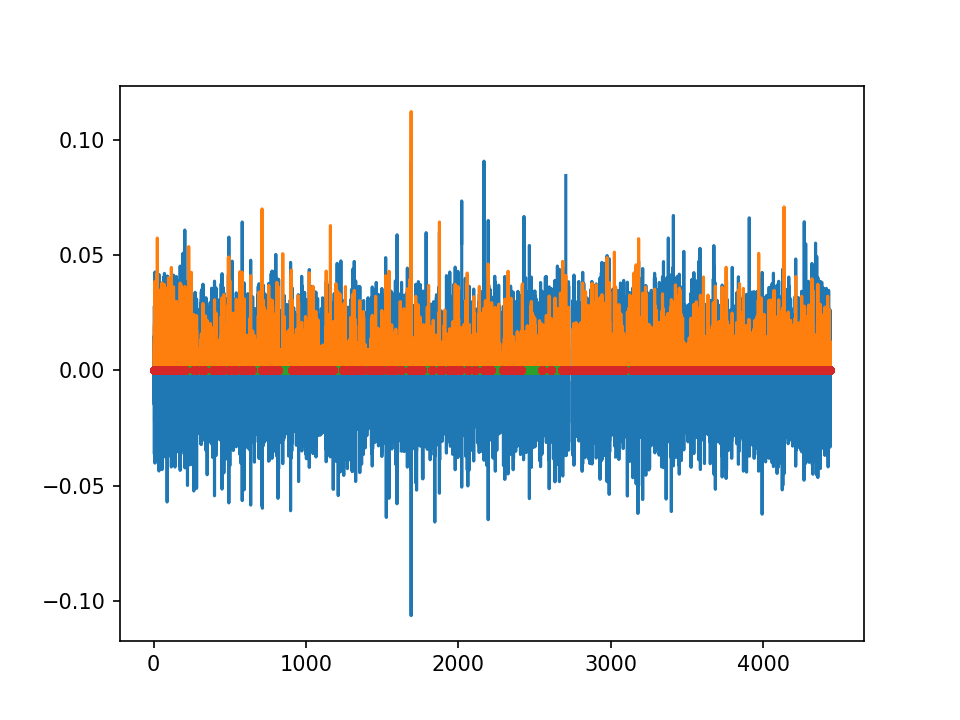

In [22]:
i=9

print(fish_ids[i])

dt=1/300
default()
widget()
fig,ax=plt.subplots(figsize=(6.4,4.8),dpi=150)
#ax.plot(t_c_list[i],vtail_c_list[i]/1000,'-')
ax.plot(t_c_list[i],dangletail_c_list[i]/1000,'-')
ax.plot(t_c_list[i],mean_thrust_c_list[i],'-')
#ax.axhline(thrust_thr_list[i],c='k')
ax.plot(t_c_list[i][mask_movetail_list[i]], np.zeros(np.sum(mask_movetail_list[i])),'.')
ax.plot(t_c_list[i][mask_notmovetail_list[i]], np.zeros(np.sum(mask_notmovetail_list[i])), '.')


#ax.set_xlim(255,255.5)
plt.show()

## on-off statistics

In [23]:
tau_on_list = []
tau_off_list = []
tau_off_list_test = []

for i in range(len(mask_movetail_list)):
    tau_on, tau_off_test = compute_tau_on_off(mask_movetail_list[i])
    tau_off, _ = compute_tau_on_off(mask_notmovetail_list[i])
    tau_on_list.append(tau_on)
    tau_off_list.append(tau_off)
    tau_off_list_test.append(tau_off_test)

In [24]:
from functions.MC_utilities import *
[color_y, color_m, color_o, color_low_boutID, color_med_boutID, color_high_boutID, color_cont, color_bout] = get_colors()
group_colors = [color_y, color_m, color_o]

# on

In [25]:
@interact(n=(0,len(tau_on_list)-1,1))
def plot(n=0):
    default()
    widget()
    fig, ax = plt.subplots(figsize=(6.4, 4.8), dpi=50)
    ax.hist(tau_on_list[n], bins=180, density=True, alpha = 0.8)
    ax.hist(bout_duration_list[n], bins=180, density=True, alpha = 0.8)
    ax.set_xlabel('tau_on (s)')
    ax.set_ylabel('Density')
    ax.set_xlim(0,4)
    plt.show()

interactive(children=(IntSlider(value=0, description='n', max=20), Output()), _dom_classes=('widget-interact',…

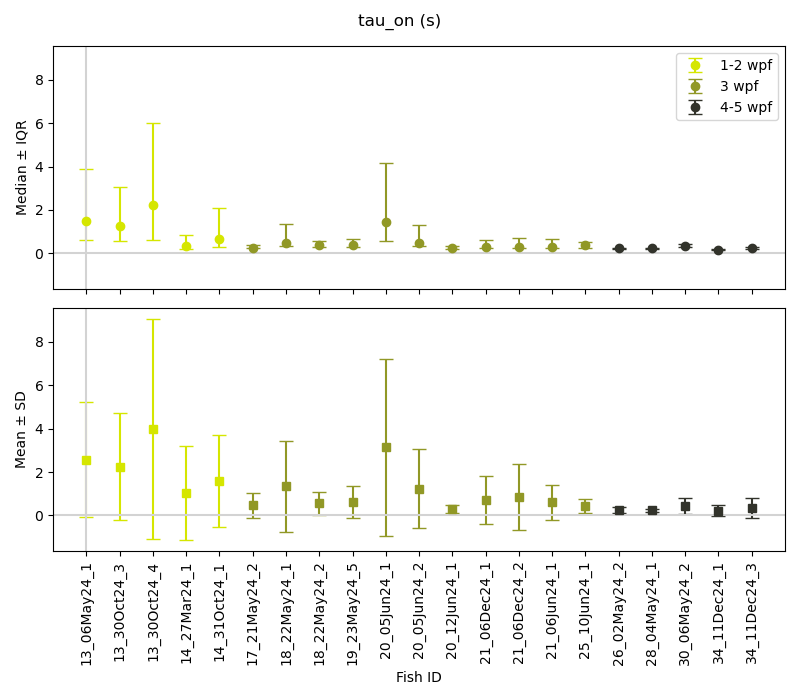

In [26]:
default()
widget()

plot_pdf_errorbars_median_and_mean(tau_on_list, fish_ids, index_groups, group_colors, title='tau_on (s)')

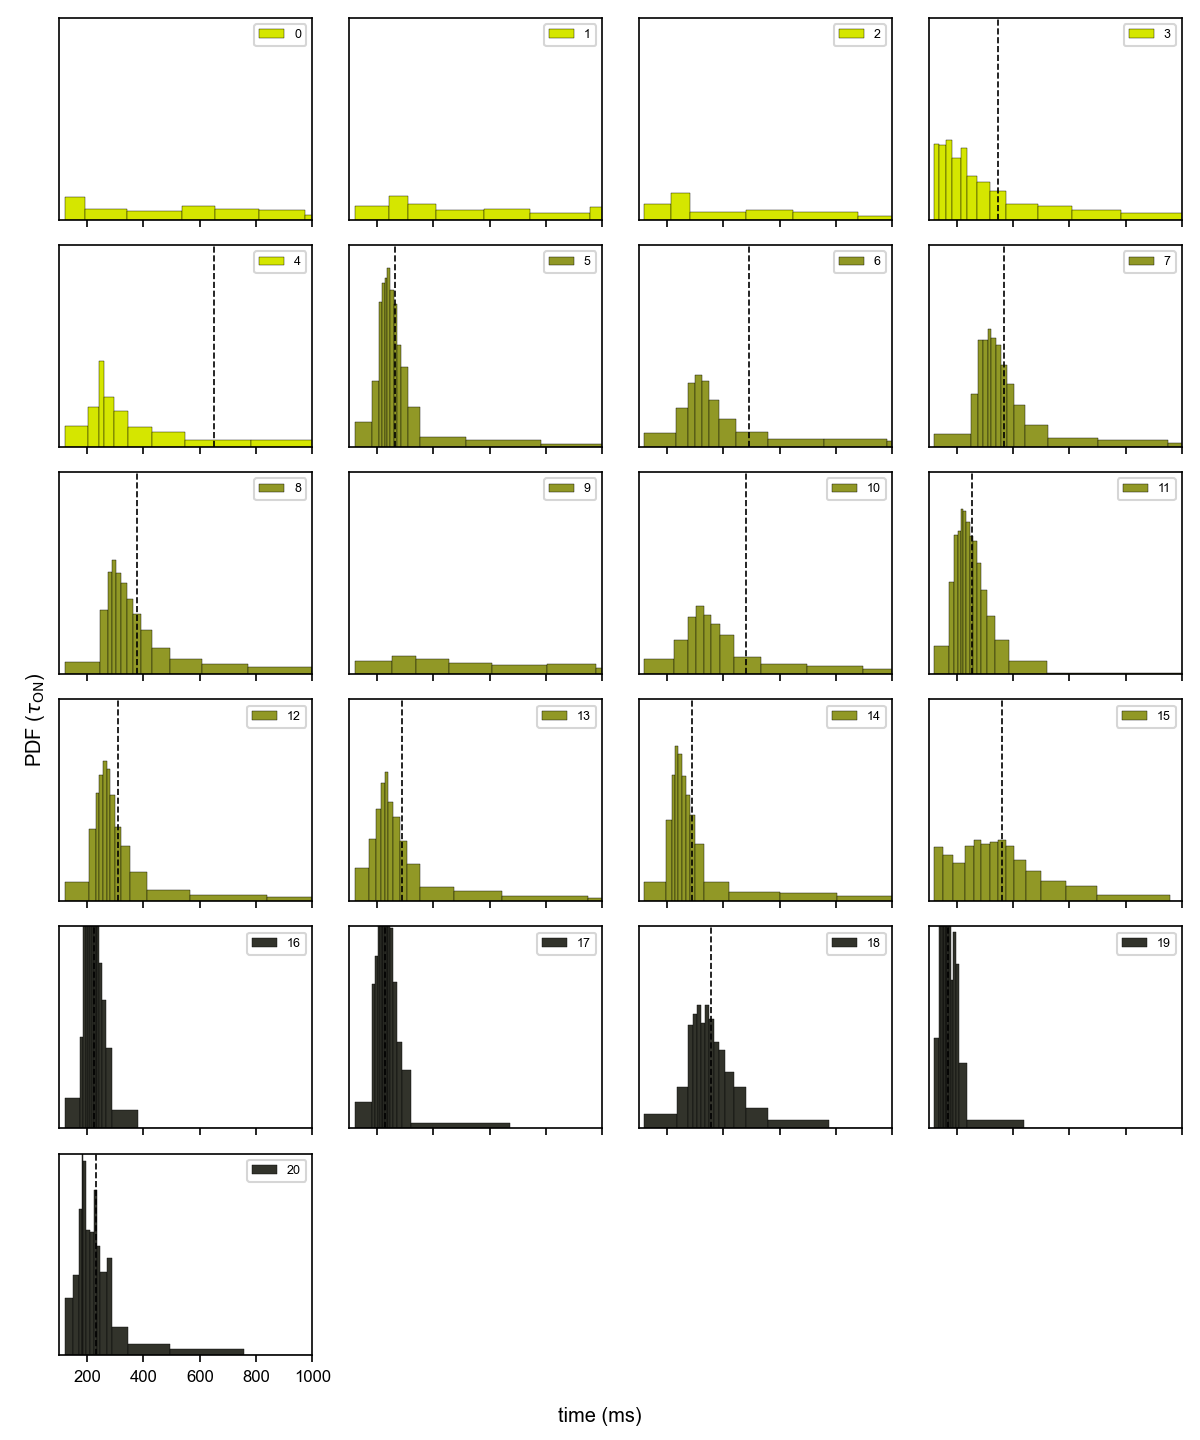

In [27]:
default()
widget()
arial()

import matplotlib.pyplot as plt
import numpy as np

# Parameters
nbins = 15
ncols = 4

# Prepare group-wise tracking
group_names = ['1-2 wpf', '3 wpf', '4-5 wpf']
group_medians = {'1-2 wpf': [], '3 wpf': [], '4-5 wpf': []}
group_colors_map = dict(zip(group_names, group_colors))

# Collect all fish as (index, group, color)
fish_entries = []
for group in group_names:
    indices = index_groups[group]
    color = group_colors_map[group]
    for i in indices:
        fish_entries.append((i, group, color))

n_fish = len(fish_entries)
nrows = int(np.ceil(n_fish / ncols))

# Create subplots
fig, axs = plt.subplots(nrows, ncols, figsize=(ncols * 2, nrows * 1.6), dpi=150, sharex=True, sharey=True)
axs = axs.flatten()

# Loop through each fish
for ax, (i, group, color) in zip(axs, fish_entries):
    data = tau_on_list[i]
    data = data[~np.isnan(data)]
    if len(data) < nbins:
        ax.axis('off')
        group_medians[group].append(np.nan)
        continue

    # Quantile-based histogram
    quantiles = np.linspace(0, 1, nbins + 1)
    bin_edges = np.quantile(data, quantiles)
    counts, _ = np.histogram(data, bins=bin_edges)
    bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
    bin_widths = bin_edges[1:] - bin_edges[:-1]
    density = counts / (np.sum(counts) * bin_widths)

    # Compute and save median
    median_val = np.median(data)
    group_medians[group].append(median_val)

    # Plot histogram and median
    ax.bar(bin_centers, density, width=bin_widths, color=color, alpha=1,
           edgecolor='black', linewidth=0.2, label=str(i))
    ax.axvline(median_val, color='black', linestyle='--', linewidth=0.8)

    # Axes formatting
    ax.set_xlim(0.1, 1)
    ax.set_ylim(0, 8)
    ax.set_xticks([0.2, 0.4, 0.6, 0.8, 1])
    ax.set_xticklabels([200, 400, 600, 800, 1000])
    ax.set_yticks([])
    ax.legend(fontsize=6)

# Hide unused subplots
for k in range(len(fish_entries), len(axs)):
    axs[k].axis('off')

# Global labels
fig.supxlabel(r'time (ms)')
fig.supylabel(r'PDF ($\tau_{\mathrm{ON}}$)')
plt.tight_layout()
plt.show()

# Convert grouped medians to NumPy arrays
tau_on_medians_young = np.array(group_medians['1-2 wpf'])
tau_on_medians_mid   = np.array(group_medians['3 wpf'])
tau_on_medians_old   = np.array(group_medians['4-5 wpf'])

In [28]:
print('tau ON statistics across fish')
print('--- young')
print(np.mean(tau_on_medians_young)*1000)
print(np.std(tau_on_medians_young)*1000)
print('--- mid')
print(np.mean(tau_on_medians_mid)*1000)
print(np.std(tau_on_medians_mid)*1000)
print('--- old')
print(np.mean(tau_on_medians_old)*1000)
print(np.std(tau_on_medians_old)*1000)

tau ON statistics across fish
--- young
1194.3333333333335
658.8462980426046
--- mid
447.7272727272728
323.8969414028755
--- old
242.00000000000006
61.59365046640586


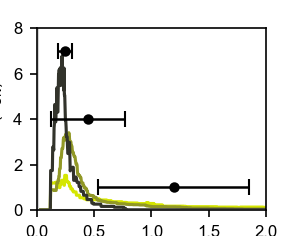

In [29]:
default()
widget()
arial()

fig, ax = plt.subplots(figsize=(5 / 2.54, 4 / 2.54), dpi=150)  # single axis
nbins = 15
x_shared = np.linspace(0, 6, 2000)  # Common x-grid for interpolation
ylim_max = 0

for j, group in enumerate(['1-2 wpf', '3 wpf', '4-5 wpf']):
    indices = index_groups[group]
    base_color = group_colors[j]

    all_interp_densities = []

    for i in indices:
        data = tau_on_list[i]
        data = data[~np.isnan(data)]
        if len(data) < nbins:
            continue

        # Quantile binning
        quantiles = np.linspace(0, 1, nbins + 1)
        bin_edges = np.quantile(data, quantiles)
        counts, _ = np.histogram(data, bins=bin_edges)
        bin_widths = bin_edges[1:] - bin_edges[:-1]
        density = counts / (np.sum(counts) * bin_widths)

        # Step-style (flattened) histogram
        step_x = np.repeat(bin_edges, 2)[1:-1]
        step_y = np.repeat(density, 2)

        # Interpolate on common x
        interp_func = interp1d(step_x, step_y, kind='previous', bounds_error=False, fill_value=0)
        interp_density = interp_func(x_shared)
        all_interp_densities.append(interp_density)

        # Plot individual
        #ax.plot(step_x, step_y, color=base_color, alpha=0.2, linewidth=0.6)

    # Plot group mean and std
    if len(all_interp_densities) > 0:
        D = np.array(all_interp_densities)
        mean_density = np.mean(D, axis=0)
        std_density = np.std(D, axis=0)
        stderr_density = std_density / np.sqrt(D.shape[0])

        ax.plot(x_shared, mean_density, color=base_color, linewidth=1.5, label=group)
       
        ylim_max = max(ylim_max, np.max(mean_density + std_density))
# Convert lists to arrays if needed and remove NaNs
tau_on_medians_young = np.array(tau_on_medians_young)
tau_on_medians_mid = np.array(tau_on_medians_mid)
tau_on_medians_old = np.array(tau_on_medians_old)

mean_y = np.nanmean(tau_on_medians_young)
mean_m = np.nanmean(tau_on_medians_mid)
mean_o = np.nanmean(tau_on_medians_old)

# Compute std for each group (excluding NaNs)
std_y = np.nanstd(tau_on_medians_young)
std_m = np.nanstd(tau_on_medians_mid)
std_o = np.nanstd(tau_on_medians_old)

# Plot shaded regions for ± std around mean
m = 0
for mean_val, std_val, color in zip([mean_y, mean_m, mean_o],
                                    [std_y, std_m, std_o],
                                    group_colors):
    #ax.axvline(mean_val, linestyle='-', color=color, linewidth=1.2, alpha=0.9, zorder=5)
    #ax.axvline(mean_val - std_val,  linestyle='--', color=color, linewidth=1, alpha=0.9, zorder=5)
    #ax.axvline(mean_val - std_val,  linestyle='--', color=color, linewidth=1, alpha=0.9, zorder=5)         
               
    ax.errorbar(mean_val, 3*m+1, xerr=std_val, fmt='o', color='black',
                capsize=4, markersize=4, elinewidth=1.2, zorder=6)
    m=m+1

ax.set_xlabel(r'time (ms)')
ax.set_xlim(0, 2)


ax.set_ylabel(r'PDF ($\tau_{\mathrm{ON}}$)')
#ax.set_yticks([])
ax.set_ylim(0, 8) #ax.set_ylim(0, 1.2 * ylim_max)

ax.axhline(0, color='lightgray')
ax.axvline(0, color='lightgray')

x value of max: 0.25250501002004005
x value of max: 0.25250501002004005
x value of max: 0.20440881763527055


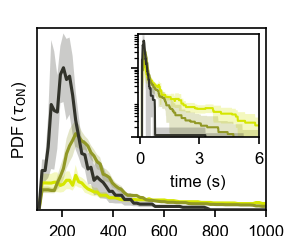

In [31]:
default()
widget()
arial()

fig, ax = plt.subplots(figsize=(5 / 2.54, 4 / 2.54), dpi=150)  # single axis
nbins = 15
x_shared = np.linspace(0, 6, 500)  # Common x-grid for interpolation
ylim_max = 0

for j, group in enumerate(['1-2 wpf', '3 wpf', '4-5 wpf']):
    indices = index_groups[group]
    base_color = group_colors[j]

    all_interp_densities = []

    for i in indices:
        data = tau_on_list[i]
        data = data[~np.isnan(data)]
        if len(data) < nbins:
            continue

        # Quantile binning
        quantiles = np.linspace(0, 1, nbins + 1)
        bin_edges = np.quantile(data, quantiles)
        counts, _ = np.histogram(data, bins=bin_edges)
        bin_widths = bin_edges[1:] - bin_edges[:-1]
        density = counts / (np.sum(counts) * bin_widths)

        # Step-style (flattened) histogram
        step_x = np.repeat(bin_edges, 2)[1:-1]
        step_y = np.repeat(density, 2)

        # Interpolate on common x
        interp_func = interp1d(step_x, step_y, kind='previous', bounds_error=False, fill_value=0)
        interp_density = interp_func(x_shared)
        all_interp_densities.append(interp_density)

        # Plot individual
        #ax.plot(step_x, step_y, color=base_color, alpha=0.2, linewidth=0.6)

    # Plot group mean and std
    if len(all_interp_densities) > 0:
        D = np.array(all_interp_densities)
        mean_density = np.mean(D, axis=0)
        std_density = np.std(D, axis=0)
        stderr_density = std_density / np.sqrt(D.shape[0])

        ax.plot(x_shared, mean_density, color=base_color, linewidth=1.5, label=group)
        #ax.fill_between(x_shared, mean_density - std_density, mean_density + std_density,color=base_color, alpha=0.25, linewidth=0)
        ax.fill_between(x_shared, mean_density - stderr_density, mean_density + stderr_density,color=base_color, alpha=0.25, linewidth=0)

        ylim_max = max(ylim_max, np.max(mean_density + std_density))

# Format main axis
ax.set_xlabel(r'time (ms)')
ax.set_xlim(0.1, 1)
ax.set_xticks([0.2, 0.4, 0.6, 0.8, 1], [200, 400, 600, 800, 1000]) #ms

ax.set_ylabel(r'PDF ($\tau_{\mathrm{ON}}$)')
ax.set_yticks([])
ax.set_ylim(0, 8) #ax.set_ylim(0, 1.2 * ylim_max)

ax.axhline(0, color='lightgray')
ax.axvline(0, color='lightgray')
#ax.legend()

# --- Log inset ---
inset_ax = ax.inset_axes([0.44, 0.4, 0.53, 0.57])
for j, group in enumerate(['1-2 wpf', '3 wpf', '4-5 wpf']):
    indices = index_groups[group]
    base_color = group_colors[j]

    all_interp_densities = []

    for i in indices:
        data = tau_on_list[i]
        data = data[~np.isnan(data)]
        if len(data) < nbins:
            continue

        quantiles = np.linspace(0, 1, nbins + 1)
        bin_edges = np.quantile(data, quantiles)
        counts, _ = np.histogram(data, bins=bin_edges)
        bin_widths = bin_edges[1:] - bin_edges[:-1]
        density = counts / (np.sum(counts) * bin_widths)

        step_x = np.repeat(bin_edges, 2)[1:-1]
        step_y = np.repeat(density, 2)

        interp_func = interp1d(step_x, step_y, kind='previous', bounds_error=False, fill_value=0)
        interp_density = interp_func(x_shared)
        all_interp_densities.append(interp_density)

        #inset_ax.plot(step_x, step_y, color=base_color, alpha=0.2, linewidth=0.5)

    if len(all_interp_densities) > 0:
        D = np.array(all_interp_densities)
        mean_density = np.mean(D, axis=0)
        std_density = np.std(D, axis=0)
        stderr_density = std_density / np.sqrt(D.shape[0])

        inset_ax.plot(x_shared, mean_density, color=base_color, linewidth=1)
        inset_ax.fill_between(x_shared, mean_density - std_density, mean_density + std_density,
                              color=base_color, alpha=0.25, linewidth=0) #std
        #inset_ax.fill_between(x_shared, mean_density - stderr_density, mean_density + stderr_density,
        #                      color=base_color, alpha=0.25, linewidth=0) #se
        max_idx = np.argmax(mean_density)
        #print("Max of mean_density:", np.max(mean_density))
        print("x value of max:", x_shared[max_idx])
   
        

inset_ax.set_xlim(-0.1, 6)
inset_ax.set_xticks([0, 3, 6])
inset_ax.set_xlabel('time (s)')
inset_ax.set_yscale("log")
inset_ax.set_ylim(10**-0.8, 1e1)
inset_ax.set_yticks([1e-2, 1e0], [])

#plt.grid()

plt.savefig(os.path.join(path_media,f'Fig_S3b_on_statistics_fish_by_fish_lin_log.pdf'),bbox_inches='tight',transparent=True,dpi=200)
plt.savefig(os.path.join(path_figures,'Fig_S3b_on_statistics_fish_by_fish_lin_log.pdf'),format = 'pdf')

plt.show()

# off

In [32]:
@interact(n=(0,len(tau_on_list)-1,1))
def plot(n=0):
    default()
    widget()
    fig, ax = plt.subplots(figsize=(6.4, 4.8), dpi=50)
    ax.hist(tau_off_list[n], bins=500, density=True, alpha = 0.5)
    ax.hist(tau_off_list_test[n], bins=500, density=True, alpha = 0.5)
    ax.axvline(0.4, color = 'red')
    ax.set_xlabel('tau_off (s)')
    ax.set_ylabel('Density')
    ax.set_xlim(0,2)
    plt.show()

interactive(children=(IntSlider(value=0, description='n', max=20), Output()), _dom_classes=('widget-interact',…

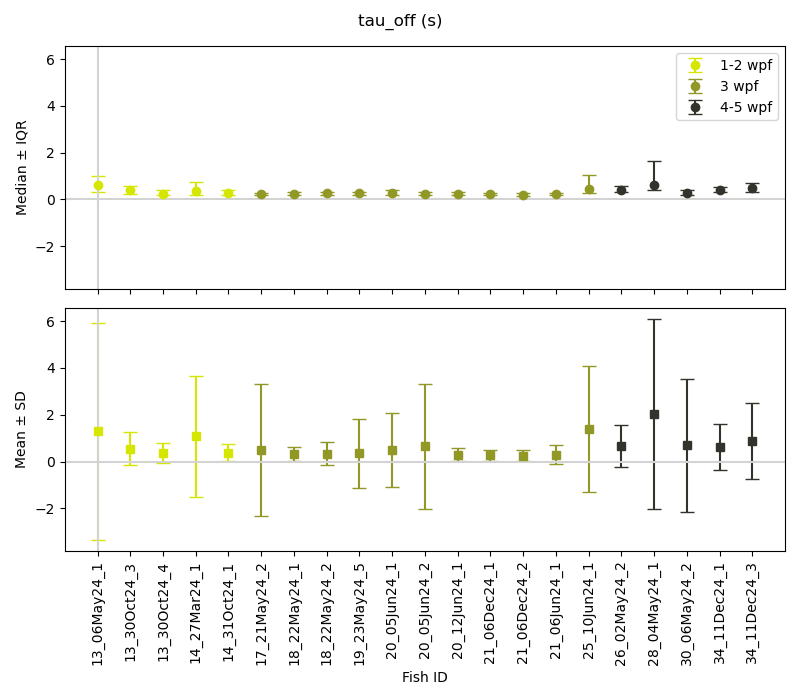

In [33]:
plot_pdf_errorbars_median_and_mean(tau_off_list, fish_ids, index_groups, group_colors, title='tau_off (s)')

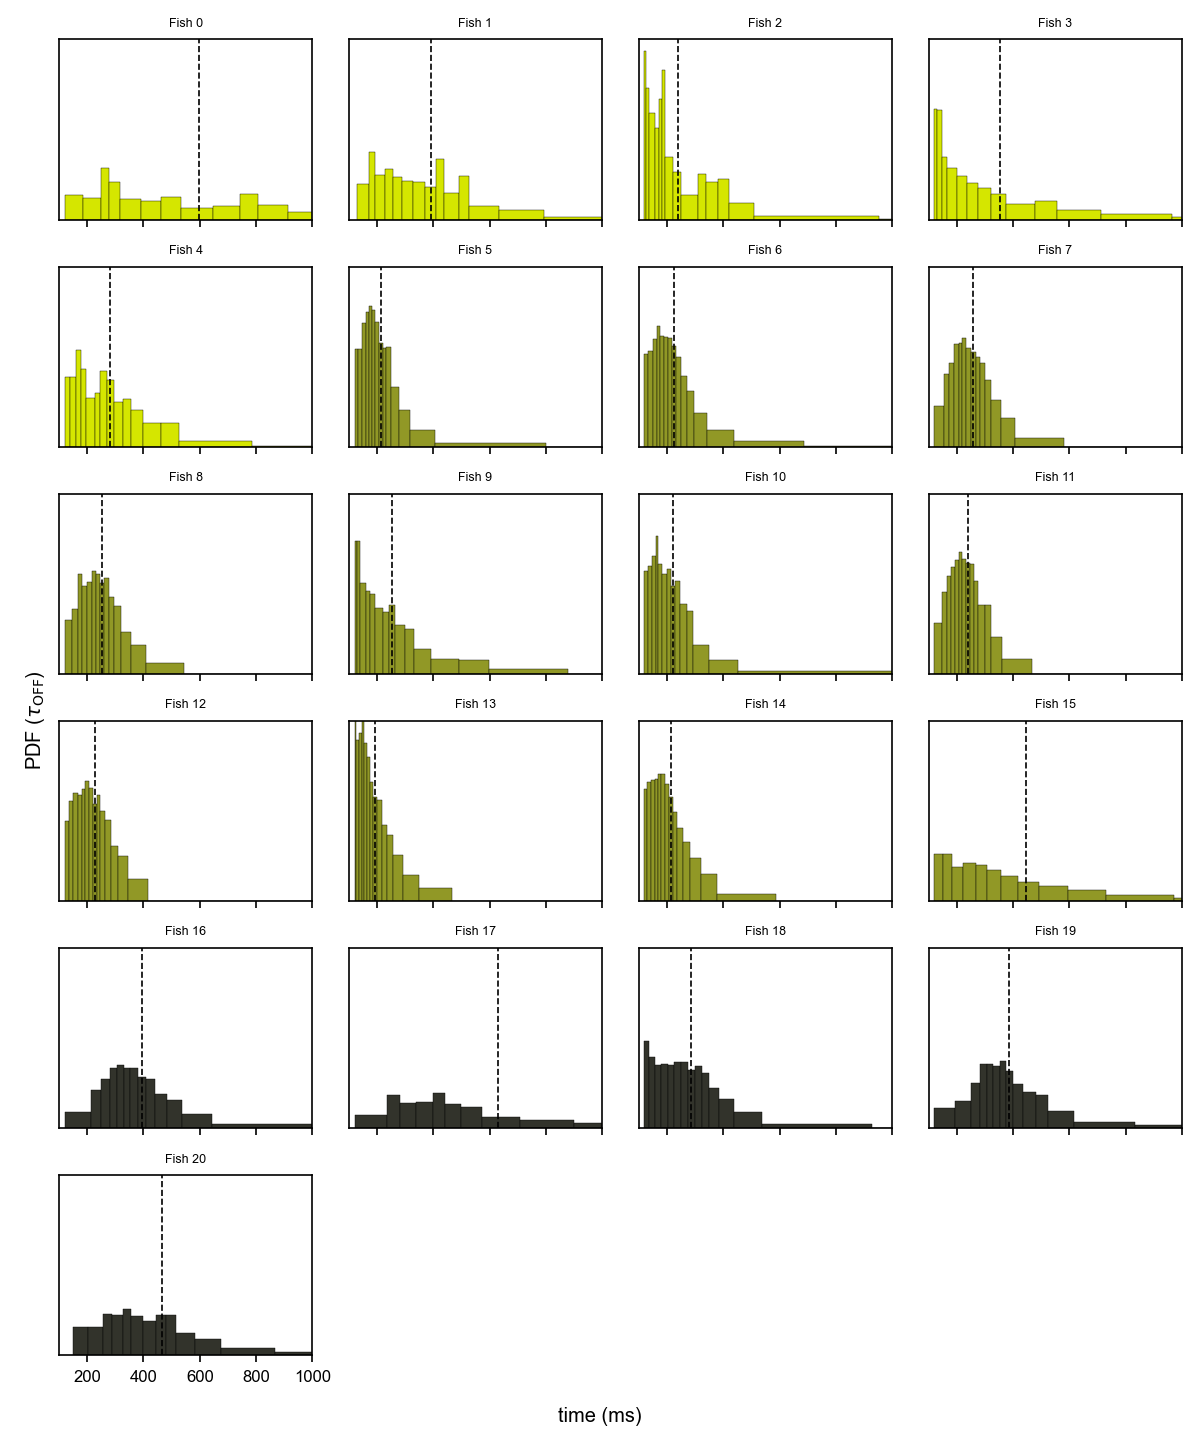

In [34]:
default()
widget()
arial()


nbins = 15
ncols = 4

# Initialize lists
tau_off_medians_young = []
tau_off_medians_mid = []
tau_off_medians_old = []

group_names = ['1-2 wpf', '3 wpf', '4-5 wpf']
group_medians = {'1-2 wpf': [], '3 wpf': [], '4-5 wpf': []}
group_colors_map = dict(zip(group_names, group_colors))

# Get all fish indices and colors with their group
fish_entries = []
for group in group_names:
    indices = index_groups[group]
    color = group_colors_map[group]
    for i in indices:
        fish_entries.append((i, group, color))

n_fish = len(fish_entries)
nrows = int(np.ceil(n_fish / ncols))

# Prepare figure
fig, axs = plt.subplots(nrows, ncols, figsize=(ncols * 2, nrows * 1.6), dpi=150, sharex=True, sharey=True)
axs = axs.flatten()

for ax, (i, group, color) in zip(axs, fish_entries):
    data = tau_off_list[i]
    data = data[~np.isnan(data)]
    if len(data) < nbins:
        ax.axis('off')
        group_medians[group].append(np.nan)
        continue

    # Histogram (quantile-based)
    quantiles = np.linspace(0, 1, nbins + 1)
    bin_edges = np.quantile(data, quantiles)
    counts, _ = np.histogram(data, bins=bin_edges)
    bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
    bin_widths = bin_edges[1:] - bin_edges[:-1]
    density = counts / (np.sum(counts) * bin_widths)

    # Compute and store median
    median_val = np.median(data)
    group_medians[group].append(median_val)

    # Plot
    ax.bar(bin_centers, density, width=bin_widths, color=color, alpha=1,
           edgecolor='black', linewidth=0.2)
    ax.axvline(median_val, color='black', linestyle='--', linewidth=0.8)
    ax.set_xlim(0.1, 1)
    ax.set_ylim(0, 8)
    ax.set_xticks([0.2, 0.4, 0.6, 0.8, 1])
    ax.set_xticklabels([200, 400, 600, 800, 1000])
    ax.set_yticks([])
    ax.set_title(f'Fish {i}', fontsize=6)

# Hide unused subplots
for k in range(len(fish_entries), len(axs)):
    axs[k].axis('off')

# Labels
fig.supxlabel(r'time (ms)')
fig.supylabel(r'PDF ($\tau_{\mathrm{OFF}}$)')
plt.tight_layout()
plt.show()

# Convert to NumPy arrays
tau_off_medians_young = np.array(group_medians['1-2 wpf'])
tau_off_medians_mid   = np.array(group_medians['3 wpf'])
tau_off_medians_old   = np.array(group_medians['4-5 wpf'])

In [35]:
print('tau OFF statistics across fish')
print('--- young')
print(np.mean(tau_off_medians_young)*1000)
print(np.std(tau_off_medians_young)*1000)
print('--- mid')
print(np.mean(tau_off_medians_mid)*1000)
print(np.std(tau_off_medians_mid)*1000)
print('--- old')
print(np.mean(tau_off_medians_old)*1000)
print(np.std(tau_off_medians_old)*1000)

tau OFF statistics across fish
--- young
372.3333333333333
124.58642694040863
--- mid
249.69696969696972
65.04783858014483
--- old
432.33333333333337
113.98635395909851


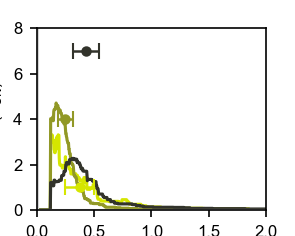

In [36]:
default()
widget()
arial()

fig, ax = plt.subplots(figsize=(5 / 2.54, 4 / 2.54), dpi=150)  # single axis
nbins = 15
x_shared = np.linspace(0, 6, 2000)  # Common x-grid for interpolation
ylim_max = 0

for j, group in enumerate(['1-2 wpf', '3 wpf', '4-5 wpf']):
    indices = index_groups[group]
    base_color = group_colors[j]

    all_interp_densities = []

    for i in indices:
        data = tau_off_list[i]
        data = data[~np.isnan(data)]
        if len(data) < nbins:
            continue

        # Quantile binning
        quantiles = np.linspace(0, 1, nbins + 1)
        bin_edges = np.quantile(data, quantiles)
        counts, _ = np.histogram(data, bins=bin_edges)
        bin_widths = bin_edges[1:] - bin_edges[:-1]
        density = counts / (np.sum(counts) * bin_widths)

        # Step-style (flattened) histogram
        step_x = np.repeat(bin_edges, 2)[1:-1]
        step_y = np.repeat(density, 2)

        # Interpolate on common x
        interp_func = interp1d(step_x, step_y, kind='previous', bounds_error=False, fill_value=0)
        interp_density = interp_func(x_shared)
        all_interp_densities.append(interp_density)

        # Plot individual
        #ax.plot(step_x, step_y, color=base_color, alpha=0.2, linewidth=0.6)

    # Plot group mean and std
    if len(all_interp_densities) > 0:
        D = np.array(all_interp_densities)
        mean_density = np.mean(D, axis=0)
        std_density = np.std(D, axis=0)
        stderr_density = std_density / np.sqrt(D.shape[0])

        ax.plot(x_shared, mean_density, color=base_color, linewidth=1.5, label=group)
       
        ylim_max = max(ylim_max, np.max(mean_density + std_density))

mean_y = np.nanmean(np.array(tau_off_medians_young))
mean_m = np.nanmean(np.array(tau_off_medians_mid))
mean_o = np.nanmean(np.array(tau_off_medians_old))

# Compute std for each group (excluding NaNs)
std_y = np.nanstd(np.array(tau_off_medians_young))
std_m = np.nanstd(np.array(tau_off_medians_mid))
std_o = np.nanstd(np.array(tau_off_medians_old))

# Plot shaded regions for ± std around mean
m = 0
for mean_val, std_val, color in zip([mean_y, mean_m, mean_o],
                                    [std_y, std_m, std_o],
                                    group_colors):
    #ax.axvline(mean_val, linestyle='-', color=color, linewidth=1.2, alpha=0.9, zorder=5)
    #ax.axvline(mean_val - std_val,  linestyle='--', color=color, linewidth=1, alpha=0.9, zorder=5)
    #ax.axvline(mean_val - std_val,  linestyle='--', color=color, linewidth=1, alpha=0.9, zorder=5)         
               
    ax.errorbar(mean_val, 3*m+1, xerr=std_val, fmt='o', color=color,
                capsize=4, markersize=4, elinewidth=1.2, zorder=6)
    m=m+1

ax.set_xlabel(r'time (ms)')
ax.set_xlim(0, 2)


ax.set_ylabel(r'PDF ($\tau_{\mathrm{ON}}$)')
#ax.set_yticks([])
ax.set_ylim(0, 8) #ax.set_ylim(0, 1.2 * ylim_max)

ax.axhline(0, color='lightgray')
ax.axvline(0, color='lightgray')

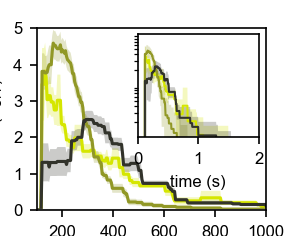

In [38]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d


default()
widget()
arial()

fig, ax = plt.subplots(figsize=(5 / 2.54, 4 / 2.54), dpi=150)  # single axis
nbins = 10
x_shared = np.linspace(0, 2, 500)  # Common x-grid for interpolation
ylim_max = 0

for j, group in enumerate(['1-2 wpf', '3 wpf', '4-5 wpf']):
    indices = index_groups[group]
    base_color = group_colors[j]

    all_interp_densities = []

    for i in indices:
        data = tau_off_list[i]
        data = data[~np.isnan(data)]
        if len(data) < nbins:
            continue

        # Quantile binning
        quantiles = np.linspace(0, 1, nbins + 1)
        bin_edges = np.quantile(data, quantiles)
        counts, _ = np.histogram(data, bins=bin_edges)
        bin_widths = bin_edges[1:] - bin_edges[:-1]
        density = counts / (np.sum(counts) * bin_widths)

        # Step-style (flattened) histogram
        step_x = np.repeat(bin_edges, 2)[1:-1]
        step_y = np.repeat(density, 2)

        # Interpolate on common x
        interp_func = interp1d(step_x, step_y, kind='previous', bounds_error=False, fill_value=0)
        interp_density = interp_func(x_shared)
        all_interp_densities.append(interp_density)

        # Plot individual
        #ax.plot(step_x, step_y, color=base_color, alpha=0.2, linewidth=0.6)

    # Plot group mean and std
    if len(all_interp_densities) > 0:
        D = np.array(all_interp_densities)
        weights = []

        # Compute weights: sqrt of number of samples per fish
        for i in indices:
            n = np.sum(~np.isnan(tau_on_list[i]))
            if n >= nbins:
                weights.append(np.sqrt(n))

        weights = np.array(weights)
        weights = weights[:len(D)]  # Make sure it matches shape of D

        # Normalize weights
        weights /= np.sum(weights)

        # Weighted mean
        mean_density = np.average(D, axis=0, weights=weights)

        # Weighted std and stderr
        variance_density = np.average((D - mean_density)**2, axis=0, weights=weights)
        stderr_density = np.sqrt(variance_density / len(weights))

        ax.plot(x_shared, mean_density, color=base_color, linewidth=1.5, label=group)
        #ax.fill_between(x_shared, mean_density - std_density, mean_density + std_density,color=base_color, alpha=0.25, linewidth=0)
        ax.fill_between(x_shared, mean_density - stderr_density, mean_density + stderr_density,color=base_color, alpha=0.25, linewidth=0)

        #ylim_max = max(ylim_max, np.max(mean_density + std_density))

# Format main axis
ax.set_xlabel(r'time (ms)')
ax.set_xlim(0.1, 1)
ax.set_xticks([0.2, 0.4, 0.6, 0.8, 1], [200, 400, 600, 800, 1000]) #ms

ax.set_ylim(0, 5) #ax.set_ylim(0, 1.2 * ylim_max)
ax.set_ylabel(r'PDF ($\tau_{\mathrm{OFF}}$)')
#ax.set_yticks([])

ax.axhline(0, color='lightgray')
ax.axvline(0, color='lightgray')
#ax.legend()


# --- Log inset ---
inset_ax = ax.inset_axes([0.44, 0.4, 0.53, 0.57])
for j, group in enumerate(['1-2 wpf', '3 wpf', '4-5 wpf']):
    indices = index_groups[group]
    base_color = group_colors[j]

    all_interp_densities = []

    for i in indices:
        data = tau_off_list[i]
        data = data[~np.isnan(data)]
        if len(data) < nbins:
            continue

        quantiles = np.linspace(0, 1, nbins + 1)
        bin_edges = np.quantile(data, quantiles)
        counts, _ = np.histogram(data, bins=bin_edges)
        bin_widths = bin_edges[1:] - bin_edges[:-1]
        density = counts / (np.sum(counts) * bin_widths)

        step_x = np.repeat(bin_edges, 2)[1:-1]
        step_y = np.repeat(density, 2)

        interp_func = interp1d(step_x, step_y, kind='previous', bounds_error=False, fill_value=0)
        interp_density = interp_func(x_shared)
        all_interp_densities.append(interp_density)

        #inset_ax.plot(step_x, step_y, color=base_color, alpha=0.2, linewidth=0.5)

    if len(all_interp_densities) > 0:
        D = np.array(all_interp_densities)
        mean_density = np.mean(D, axis=0)
        std_density = np.std(D, axis=0)
        stderr_density = std_density / np.sqrt(D.shape[0])

        inset_ax.plot(x_shared, mean_density, color=base_color, linewidth=1)
        inset_ax.fill_between(x_shared, mean_density - std_density, mean_density + std_density, color=base_color, alpha=0.25, linewidth=0) #std
        #inset_ax.fill_between(x_shared, mean_density - stderr_density, mean_density + stderr_density, color=base_color, alpha=0.25, linewidth=0) #se

inset_ax.set_yscale("log")
inset_ax.set_xlim(0, 2)
inset_ax.set_ylim(1e-1, 1e1)
inset_ax.set_yticks([])
inset_ax.set_xticks([0, 1, 2])
inset_ax.set_xlabel(r'time (s)')

# Save or show
plt.savefig(os.path.join(path_media,f'Fig_S3c_off_statistics_fish_by_fish_lin_log.pdf'),bbox_inches='tight',transparent=True,dpi=200)
plt.savefig(os.path.join(path_figures,'Fig_S3c_off_statistics_fish_by_fish_lin_log.pdf'),format = 'pdf')

plt.show()

## SI figure - single fish examples

In [39]:
#selected fish id:
## y : 2-3-4
## m : 6-7-12
## y : 16-17-20

In [40]:
from scipy.optimize import curve_fit


def exp_pdf(t, tau):
    return (1 / tau) * np.exp(-t / tau)

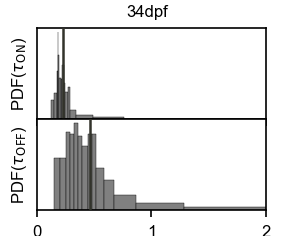

In [43]:
default()
widget()
arial()

# Select the fish index to plot
fish_idx = 20# change this as needed

# Get data and clean NaNs
data_on = tau_on_list[fish_idx]
data_on = data_on[~np.isnan(data_on)]

data_off = tau_off_list[fish_idx]
data_off = data_off[~np.isnan(data_off)]

# Number of quantile bins
nbins = 15

# Compute quantile-based histogram for τ_on
quantiles_on = np.linspace(0, 1, nbins + 1)
bin_edges_on = np.quantile(data_on, quantiles_on)
counts_on, _ = np.histogram(data_on, bins=bin_edges_on)
bin_centers_on = 0.5 * (bin_edges_on[:-1] + bin_edges_on[1:])
bin_widths_on = bin_edges_on[1:] - bin_edges_on[:-1]
density_on = counts_on / (np.sum(counts_on) * bin_widths_on)

# Compute quantile-based histogram for τ_off
quantiles_off = np.linspace(0, 1, nbins + 1)
bin_edges_off = np.quantile(data_off, quantiles_off)
counts_off, _ = np.histogram(data_off, bins=bin_edges_off)
bin_centers_off = 0.5 * (bin_edges_off[:-1] + bin_edges_off[1:])
bin_widths_off = bin_edges_off[1:] - bin_edges_off[:-1]
density_off = counts_off / (np.sum(counts_off) * bin_widths_off)

# Create 1x2 subplot
fig, axs = plt.subplots(2,1, figsize=(5 / 2.54, 4 / 2.54), dpi=150, sharex = True)
fig.subplots_adjust(hspace=0)
# τ_on
axs[0].bar(bin_centers_on, density_on, width=bin_widths_on, color='gray',
           edgecolor='black', linewidth=0.2)
axs[0].set_xlabel(r'time (s)')
axs[0].set_ylabel(r'PDF($\tau_{\mathrm{ON}}$)')
axs[0].set_yticks([])


# τ_off
axs[1].bar(bin_centers_off, density_off, width=bin_widths_off, color='gray',
           edgecolor='black', linewidth=0.2)
axs[1].set_xlabel(r'time (s)')
axs[1].set_ylabel(r'PDF($\tau_{\mathrm{OFF}}$)')
axs[1].set_xlim(0, 2)
axs[1].set_yticks([])
axs[1].set_xticks([0,1,2])

# Determine group for selected fish
group_names = ['1-2 wpf', '3 wpf', '4-5 wpf']
group_color = None
for group_name, color in zip(group_names, group_colors):
    if fish_idx in index_groups[group_name]:
        group_color = color
        break

# Compute medians
median_on = np.median(data_on)
median_off = np.median(data_off)

# Plot median lines
axs[0].axvline(median_on, color=group_color, linestyle='-', linewidth=1.2, zorder=5)
axs[1].axvline(median_off, color=group_color, linestyle='-', linewidth=1.2, zorder=5)
fig.suptitle(str(fish_ids[fish_idx][:2]) + 'dpf')


tau_on_fit = None
tau_off_fit = None

if fish_idx < 5:
    print('FIT EXP')
    try:
        popt_on, _ = curve_fit(exp_pdf, bin_centers_on, density_on, p0=[np.mean(data_on)])
        tau_on_fit = popt_on[0]
        axs[0].plot(bin_centers_on, exp_pdf(bin_centers_on, tau_on_fit),
                    color=group_color, linestyle='--', linewidth=1.2, label = f'exp.={tau_on_fit:.1f}s')
        axs[0].legend()
    except Exception as e:
        tau_on_fit = None

    # Fit τ_off
    try:
        popt_off, _ = curve_fit(exp_pdf, bin_centers_off, density_off, p0=[np.mean(data_off)])
        tau_off_fit = popt_off[0]
        axs[1].plot(bin_centers_off, exp_pdf(bin_centers_off, tau_off_fit),
                    color=group_color, linestyle='--', linewidth=1.2, label = f'exp.={tau_off_fit:.1f}s')
        axs[1].legend()
    except Exception as e:
        tau_off_fit = None


# Add caption with fitted tau values if available
title = f"{fish_ids[fish_idx][:2]}dpf"
fig.suptitle(title, fontsize=8)

plt.savefig(os.path.join(path_media,f'Fig_S3a_example_on_off_single_fish.pdf'),bbox_inches='tight',transparent=True,dpi=200)
plt.savefig(os.path.join(path_figures,'Fig_S3a_example_on_off_single_fish.pdf'),format = 'pdf')

plt.show()